#1. Selección y alcance del dataset













##1.1 Descripción del dataset elegido
---
*   Nombre/Fuente: Secretaria de Transporte
*   Link de descarga: [Aterrizajes y despegues procesados por ANAC en el año 2026](https://datos.transporte.gob.ar/dataset/aterrizajes-y-despegues-procesados-por-la-administracion-nacional-de-aviacion-civil-anac/archivo/7b6d0103-0a69-4c67-aed9-33cb58ae12f5)
* Descripción: dataset contiene los aterrizajes y despegues procesados por la Administración Nacional de Aviación Civil (ANAC) en el año 2026.
*   Formato: .csv
* Diccionario de data set con unidades:

|Nombre|Tipo|Definición|
|---|---|---|
|Fecha UTC|date|Fecha de vuelo UTC.|
|Hora UTC|date|Hora UTC (Tiempo Universal Coordinado). Al evaluar el dato, considerar que Argentina tiene hora oficial UTC -3.|
|Clase de Vuelo (todos los vuelos)|object|Categorías de vuelos.|
|Clasificación Vuelo|object|Clasificación del tipo de vuelo: doméstico (cabotaje) o internacional.|  
|Tipo de Movimiento|object|Clasificación del tipo de movimiento. Se considera "Movimiento" a una operación, sea aterrizaje o despegue de una aeronave en un aeropuerto.|
|Aeropuerto|object|Nombre del aeropuerto código FAA.|
|Origen / Destino|object|Se utiliza el código FAA para aeropuertos nacionales y OACI para aeropuertos extranjeros.|
|Aerolinea Nombre|object|Nombre de la línea aérea.|
|Aeronave|object|Código para identificar a los fabricantes de las aeronaves con la designación específica del modelo del avión.|
|Matrícula|object|Matrícula o modelo del avión que realiza la operación.|
|Pasajeros|int|Cantidad de pasajeros operación individual (despegue/aterrizaje). Para vuelos de cabotaje se registra despegue y aterrizaje. Al analizar un Aeropuerto individual se debe tomar el dato de esta columna.|
|PAX|int|1pax=1tarjeta de embarque. Usar esta columna al analizar la cantidad de pasajeros cabotaje a nivel total país. Al analizar los pasajeros internacionales es indiferente usar esta columna o la anterior.|
|Calidad dato|object|La información correspondiente a los últimos dos meses es de carácter provisorio y puede estar sujeta a modificaciones.|

---
**Aclaraciones:**


1.   En "Origen/Destino" indica: el Aeropuerto de procedencia (si fue aterrizaje) o de destino (si fue despegue).

2.   En "Aerolinea Nombre", cuando no opera una aerolínea comercial (vuelo privado/civil/escuela/no regular), se registra un 0.

3. En "Aeronave", cuando el modelo específico de la aeronave no pudo ser identificado o codificado por el sistema de la ANAC al momento del registro, se indica un 0.

4. "Pasajeros" contaría los mismo que "PAX", porque son lo mismo, osea los pasajeros que se transportan. Sin embargo, la diferencia radica en el registro de los vuelos de cabotaje (doméstico/nacional). En "Pasajeros", los vuelos de cabotaje generan dos registros de la cantidad de pasajeros, uno al despegar y otro al aterrizar.
Ejemplo:

|Tipo de Movimiento|Aeropuerto|Origen/Destino|Pasajeros|PAX|
|---|---|---|---|---|
|Despegue|EZE|TRE|88|44|
|Aterrizaje|TRE|EZE|88|44|


 En el ejemplo puede observarse como "Pasajeros" cuenta 2 (dos) veces a los pasajeros: una vez en el despegue y por segunda vez en el aterrizaje. La realidad es que en ese vuelo viajan 88 pasajeros.
"PAX" registra el número real de pasajeros, el registro se hace desglosando el número en despegue y aterrizaje para que al sumar las cantidades resulte el valor real. En el ejemplo 44 + 44 resulta 88.

5. El caso de vuelos internacionales no es como los domésticos, sólo se registra una vez: *despegue* o *aterrizaje*. Tanto "Pasajeros" como "PAX" registran el mismo número de pasajeros. No ocurre como en los vuelos de cabotaje que al moverse 2 veces dentro del país deben registrarse dos veces (despegue y aterrizaje).

6. "Calidad de dato" describe el estado del registro. Si es *provisorio* significa que aún no fue auditado, osea que está sujeto a modificación; si es *definitivo* significa que ya fue auditado, es un dato consolidado oficial.



##1.2 Investigación
---
1. Se solicita hallar:
   * los 5 (cinco) aeropuertos con mayor actividad aérea (despegues y aterrizajes) en el país.
   * cuales son los 5 (cinco) aeropuertos con mayor tráfico de pasajeros.
   * del aeropuerto con mayor tráfico de pasajeros, el flujo de pasajeros por mes.
   * del aeropuerto con mayor tráfico de pasajeros, la clase de vuelo que predomina según el volumen de pasajeros.
  
2.  Se solicita el flujo por mes del tráfico nacional e internacional de pasajeros dentro del país.



---
#2. Carga del Dataset

In [ ]:
#Importación de librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


ruta_archivo="/content/drive/MyDrive/202609-informe-ministerio-vf-matricula.csv"
data_aereo=pd.read_csv(ruta_archivo,sep=";")
data_aereo


,Fecha UTC,Hora UTC,Clase de Vuelo (todos los vuelos),Clasificación Vuelo,Tipo de Movimiento,Aeropuerto,Origen / Destino,Aerolinea Nombre,Aeronave,Matrícula,Pasajeros,PAX,Calidad dato
0,01/01/2026,0:01,Regular,Doméstico,Despegue,AER,SIS,JETSMART AIRLINES S.A.,AIB-A320-232,LV-IVO,155,78,DEFINITIVO
1,01/01/2026,0:04,Regular,Doméstico,Aterrizaje,TUC,AER,JETSMART AIRLINES S.A.,AIB-A320-232,LV-HEK,148,74,DEFINITIVO
2,01/01/2026,0:05,Regular,Internacional,Aterrizaje,AER,SBGR,LATAM AIRLINES BRASIL (exTAM LA SA),0,PRTYV,48,48,DEFINITIVO
3,01/01/2026,0:06,Regular,Doméstico,Despegue,IGU,EZE,JETSMART AIRLINES S.A.,AIB-A320-232,LV-HVT,78,39,DEFINITIVO
4,01/01/2026,0:08,Regular,Internacional,Despegue,AER,SCEL,LATAM AIRLINES GROUP S.A.(exLAN AIRLINE),0,CCCOG,168,168,DEFINITIVO
...,...,...,...,...,...,...,...,...,...,...,...,...,...
419257,30/09/2026,23:55,Regular,Internacional,Aterrizaje,AER,SBGR,GOL LINHAS AÉREAS S.A.,0,PRGZV,165,165,PROVISORIO
419258,30/09/2026,23:56,Regular,Internacional,Despegue,AER,SCEL,LATAM AIRLINES GROUP S.A.(exLAN AIRLINE),0,CCBHL,162,162,PROVISORIO
419259,30/09/2026,23:56,Regular,Internacional,Despegue,AER,SCEL,LATAM AIRLINES GROUP S.A.(exLAN AIRLINE),0,CCBHL,135,135,PROVISORIO
419260,30/09/2026,23:57,Regular,Internacional,Despegue,EZE,KMIA,AMERICAN AIRLINES INC.,0,N788AN,257,257,PROVISORIO


#3. Exploración de datos

## 3.1 Exploración estructural

In [ ]:
print("Dimensiones:",data_aereo.shape)

Dimensiones: (419262, 13)


### 3.1.1 Formatos y tipos
---
**int64: números enteros**

**object: texto**

**float64: números decimales**

In [ ]:
data_aereo.info() #para detectar columnas con valores faltantes o inconsistencias

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 419262 entries, 0 to 419261
Data columns (total 13 columns):
 #   Column                             Non-Null Count   Dtype 
---  ------                             --------------   ----- 
 0   Fecha UTC                          419262 non-null  object
 1   Hora UTC                           419262 non-null  object
 2   Clase de Vuelo (todos los vuelos)  419262 non-null  object
 3   Clasificación Vuelo                419262 non-null  object
 4   Tipo de Movimiento                 419262 non-null  object
 5   Aeropuerto                         419262 non-null  object
 6   Origen / Destino                   419262 non-null  object
 7   Aerolinea Nombre                   419262 non-null  object
 8   Aeronave                           419262 non-null  object
 9   Matrícula                          419262 non-null  object
 10  Pasajeros                          419262 non-null  int64 
 11  PAX                                419262 non-null  

*   Se observan 11 variables categóricas y 2 variables numéricas.
*   No hay faltantes en las columnas.





In [ ]:
#Se realiza una visualización de las 5 primeras filas.
data_aereo.head()

,Fecha UTC,Hora UTC,Clase de Vuelo (todos los vuelos),Clasificación Vuelo,Tipo de Movimiento,Aeropuerto,Origen / Destino,Aerolinea Nombre,Aeronave,Matrícula,Pasajeros,PAX,Calidad dato
0,01/01/2026,0:01,Regular,Doméstico,Despegue,AER,SIS,JETSMART AIRLINES S.A.,AIB-A320-232,LV-IVO,155,78,DEFINITIVO
1,01/01/2026,0:04,Regular,Doméstico,Aterrizaje,TUC,AER,JETSMART AIRLINES S.A.,AIB-A320-232,LV-HEK,148,74,DEFINITIVO
2,01/01/2026,0:05,Regular,Internacional,Aterrizaje,AER,SBGR,LATAM AIRLINES BRASIL (exTAM LA SA),0,PRTYV,48,48,DEFINITIVO
3,01/01/2026,0:06,Regular,Doméstico,Despegue,IGU,EZE,JETSMART AIRLINES S.A.,AIB-A320-232,LV-HVT,78,39,DEFINITIVO
4,01/01/2026,0:08,Regular,Internacional,Despegue,AER,SCEL,LATAM AIRLINES GROUP S.A.(exLAN AIRLINE),0,CCCOG,168,168,DEFINITIVO


In [ ]:
#Tipo de dato que contiene cada columna.
data_aereo.dtypes

,0
Fecha UTC,object
Hora UTC,object
Clase de Vuelo (todos los vuelos),object
Clasificación Vuelo,object
Tipo de Movimiento,object
Aeropuerto,object
Origen / Destino,object
Aerolinea Nombre,object
Aeronave,object
Matrícula,object


Observaciones:
Tipos de datos incorrectos:


* Fecha UTC object:->date
* Hora UTC: object->date

Por lo tanto, se tendrían: 2 datos cuantitativos, 2 temporales y 9 categóricos.





### 3.1.2 Valores Nulos y Faltantes
---



In [ ]:
# Se busca ver cuántas celdas vacías hay por columna.
data_aereo.isnull().sum()

,0
Fecha UTC,0
Hora UTC,0
Clase de Vuelo (todos los vuelos),0
Clasificación Vuelo,0
Tipo de Movimiento,0
Aeropuerto,0
Origen / Destino,0
Aerolinea Nombre,0
Aeronave,0
Matrícula,0


Observaciones: No hay celdas vacías.

In [ ]:
# En el dataset se registran con un 0 los datos faltantes/desconocidos.
# Por ejemplo: cuando no se conoce el modelo de aeronaveo o el nombre de la aerolínea por ser un vuelo de escuela.
# Para saber cuántas veces se cumple exactamente esta condición:

total_fec = (data_aereo['Fecha UTC'] == '0').sum()
total_hor = (data_aereo['Hora UTC'] == '0').sum()
total_clas = (data_aereo['Clase de Vuelo (todos los vuelos)'] == '0').sum()
total_clvue = (data_aereo['Clasificación Vuelo'] == '0').sum()
total_mov = (data_aereo['Tipo de Movimiento'] == '0').sum()
total_airp = (data_aereo['Aeropuerto'] == '0').sum()
total_oyd = (data_aereo['Origen / Destino'] == '0').sum()
total_airl = (data_aereo['Aerolinea Nombre'] == '0').sum()
total_nave = (data_aereo['Aeronave'] == "0").sum()
total_matric = (data_aereo['Matrícula'] == '0').sum()
total_pasaj = (data_aereo['Pasajeros'] == 0).sum()
total_pax = (data_aereo['PAX'] == 0).sum()
total_cal = (data_aereo['Calidad dato'] == '0').sum()


print(f"En Fecha UTC el valor aparece {total_fec} veces.")
print(f"En Hora UTC el valor aparece {total_hor} veces.")
print(f"En Clase de Vuelo (todos los vuelos) el valor aparece {total_clas} veces.")
print(f"En Clasificación Vuelo el valor aparece {total_clvue} veces.")
print(f"En Tipo de Movimiento el valor aparece {total_mov} veces.")
print(f"En Aeropuerto el valor aparece {total_airp} veces.")
print(f"En Origen / Destino el valor aparece {total_oyd} veces.")
print(f"En Aerolinea Nombre el valor aparece {total_airl} veces.")
print(f"En Aeronave el valor aparece {total_nave} veces.")
print(f"En Matrícula el valor aparece {total_matric} veces.")
print(f"En Pasajeros el valor aparece {total_pasaj} veces.")
print(f"En PAX el valor aparece {total_pax} veces.")
print(f"En Calidad dato el valor aparece {total_cal} veces.")

En Fecha UTC el valor aparece 0 veces.
En Hora UTC el valor aparece 0 veces.
En Clase de Vuelo (todos los vuelos) el valor aparece 0 veces.
En Clasificación Vuelo el valor aparece 0 veces.
En Tipo de Movimiento el valor aparece 0 veces.
En Aeropuerto el valor aparece 0 veces.
En Origen / Destino el valor aparece 0 veces.
En Aerolinea Nombre el valor aparece 133518 veces.
En Aeronave el valor aparece 112778 veces.
En Matrícula el valor aparece 0 veces.
En Pasajeros el valor aparece 125962 veces.
En PAX el valor aparece 125962 veces.
En Calidad dato el valor aparece 0 veces.


Observaciones:

Las columnas 'Aerolinea Nombre', 'Aeronave', 'Pasajeros' y 'PAX' tienen datos faltantes:
* En 'Aerolinea Nombre' puede deberse a que no es una línea comercial, también puede tratrase de vuelos no regulares y privados.
* En 'Aeronave' tal vez no se registró el modelo.
* En 'Pasajeros' y 'PAX' pueden ser vuelos vacíos o fantasma.

In [ ]:
# Porcentaje de datos faltantes

porcentaj1 =(data_aereo['Aerolinea Nombre'] == '0').mean() * 100
porcentaj2 =(data_aereo['Aeronave'] == '0').mean() * 100
porcentaj3 =(data_aereo['Pasajeros'] == 0).mean() * 100
porcentaj4 =(data_aereo['PAX'] == 0).mean() * 100

print(f"El porcentaje de faltantes en la columna Aerolinea Nombre es: {porcentaj1:.2f}%")
print(f"El porcentaje de faltantes en la columna Aeronave es: {porcentaj2:.2f}%")
print(f"El porcentaje de faltantes en la columna Pasajeros es: {porcentaj3:.2f}%")
print(f"El porcentaje de faltantes en la columna PAX es: {porcentaj4:.2f}%")

El porcentaje de faltantes en la columna Aerolinea Nombre es: 31.85%
El porcentaje de faltantes en la columna Aeronave es: 26.90%
El porcentaje de faltantes en la columna Pasajeros es: 30.04%
El porcentaje de faltantes en la columna PAX es: 30.04%


### 3.1.3 Duplicados

In [ ]:
# Para conocer cuantas filas duplicadas exactas hay
data_aereo.duplicated().sum()

np.int64(25)

Observaciones: Existen 25 filas duplicadas.

In [ ]:
data_aereo[data_aereo.duplicated(keep=False)]

,Fecha UTC,Hora UTC,Clase de Vuelo (todos los vuelos),Clasificación Vuelo,Tipo de Movimiento,Aeropuerto,Origen / Destino,Aerolinea Nombre,Aeronave,Matrícula,Pasajeros,PAX,Calidad dato
27652,17/01/2026,21:31,Regular,Internacional,Despegue,AER,SBGR,LATAM AIRLINES BRASIL (exTAM LA SA),0,PRXBS,166,166,DEFINITIVO
27653,17/01/2026,21:31,Regular,Internacional,Despegue,AER,SBGR,LATAM AIRLINES BRASIL (exTAM LA SA),0,PRXBS,166,166,DEFINITIVO
32962,20/01/2026,23:40,Regular,Internacional,Despegue,AER,SBFL,GOL LINHAS AÉREAS S.A.,0,PSGRI,162,162,DEFINITIVO
32963,20/01/2026,23:40,Regular,Internacional,Despegue,AER,SBFL,GOL LINHAS AÉREAS S.A.,0,PSGRI,162,162,DEFINITIVO
36195,22/01/2026,19:52,Regular,Internacional,Aterrizaje,AER,SULS,GOL LINHAS AÉREAS S.A.,0,PRXMO,120,120,DEFINITIVO
36196,22/01/2026,19:52,Regular,Internacional,Aterrizaje,AER,SULS,GOL LINHAS AÉREAS S.A.,0,PRXMO,120,120,DEFINITIVO
50752,31/01/2026,0:25,Regular,Internacional,Aterrizaje,AER,SBGR,LATAM AIRLINES BRASIL (exTAM LA SA),0,PRMBF,171,171,DEFINITIVO
50753,31/01/2026,0:25,Regular,Internacional,Aterrizaje,AER,SBGR,LATAM AIRLINES BRASIL (exTAM LA SA),0,PRMBF,171,171,DEFINITIVO
52780,01/02/2026,9:13,Regular,Internacional,Despegue,AER,SPJC,SKY AIRLINE S.A.,0,CCAZI,170,170,DEFINITIVO
52781,01/02/2026,9:13,Regular,Internacional,Despegue,AER,SPJC,SKY AIRLINE S.A.,0,CCAZI,170,170,DEFINITIVO


### 3.1.4  Inconsistencias de escritura
---


In [ ]:

# Inconsistencias de escritura

print(data_aereo["Clase de Vuelo (todos los vuelos)"].unique())
print("")
print(data_aereo["Clasificación Vuelo"].unique())
print("")
print(data_aereo["Tipo de Movimiento"].unique())
print("")
print(data_aereo["Aeropuerto"].unique())
print("")
print(data_aereo["Calidad dato"].unique())
print("")


['Regular' 'No Regular' 'Vuelo Privado con Matrícula Nacional'
 'Vuelo Privado con Matrícula Extranjera' 'Vuelo Escuela'
 'Vuelo Oficial Nacional' 'Trabajo Aéreo' 'Vuelo de Adiestramiento'
 'Vuelo Oficial Extranjero']

['Doméstico' 'Internacional']

['Despegue' 'Aterrizaje']

['AER' 'TUC' 'IGU' 'NEU' 'EZE' 'BAR' 'DOZ' 'FDO' 'SAL' 'CBA' 'SIS' 'ROS'
 'GRA' 'TRE' 'CRV' 'ECA' 'SVO' 'MDP' 'CAT' 'DIA' 'POS' 'JUA' 'MOR' 'GAL'
 'USU' 'SDE' 'CHP' 'VIE' 'FSA' 'ESQ' 'JUJ' 'TRC' 'DRY' 'CRR' 'BCA' 'SRA'
 'TRH' 'LAR' 'PAR' 'GPI' 'UIS' 'SRC' 'RTA' 'OSA' 'RYD' 'PAL' 'DIL' 'GOY'
 'MLG' 'DOL']

['DEFINITIVO' 'PROVISORIO']



Observaciones: No se han observado inconsistencias de escritura.

### 3.1.5 Columnas sin utilidad (varianza nula)

In [ ]:
# --- Columnas sin utilidad (varianza nula) ---
# Una columna con 1 solo valor único no discrimina nada: no aporta información
unicos = data_aereo.nunique()
print(unicos.sort_values())

columnas_varianza_nula = unicos[unicos <= 1].index.tolist()
print("\nColumnas con varianza nula:", columnas_varianza_nula)

Clasificación Vuelo                     2
Tipo de Movimiento                      2
Calidad dato                            2
Clase de Vuelo (todos los vuelos)       9
Aeropuerto                             50
Fecha UTC                             273
PAX                                   377
Pasajeros                             377
Aeronave                              645
Aerolinea Nombre                      926
Origen / Destino                     1128
Hora UTC                             1440
Matrícula                            4564
dtype: int64

Columnas con varianza nula: []


Observaciones: no hay columnas que contengan ningún dato.

##3.2 Exploración estadística inicial

In [ ]:
# --- Rangos anómalos ---
data_aereo.describe()

,Pasajeros,PAX
count,419262.000000,419262.000000
mean,89.019723,60.178003
std,80.771430,66.260420
min,0.000000,0.000000
25%,0.000000,0.000000
50%,91.000000,47.000000
75%,157.000000,85.000000
max,391.000000,391.000000


Consideraciones: tener en cuenta que 'Pasajeros' incluye en algunos casos valores dobles por los vuelos de cabotaje, por lo tanto se están adicionando pasajeros que no existen. También considerar que el dataset no proporciona las cantidades de pasajeros por vuelo sino según *despegue* y/o *aterrizaje*.
Los valores aquí vistos están muy alterados. Los valores más fiables podrían estar en "PAX".

Observaciones en "PAX":
* **mean y 50%:** siendo el promedio aproximadamente 60 pasajeros es superior a la mediana de 47 pasajeros.

* **min**: el valor mínimo de pasajeros nulo. Estos pueden ser vuelos vacíos o fantasma.

* **max**: El	mayor número de pasajeros registrado es de 391 en un vuelo.







## 3.3 Diagnóstico de datos

### 3.3.1 Tabla de hallazgos del diagnóstico
---


| # | Dimensión | Problema detectado | Evidencia (método/salida) | Acción propuesta |
|---|---|---|---|---|
| **1**|**Nulos** | datos faltantes | Aerolinea Nombre: 31.85%| No se toma ninguna acción.||||Aeronave: 26.90%|Se elimina esta columna, es prescindible.
||||Pasajeros: 30.04%| No se toma ninguna acción.
||||PAX : 30.04% |No se toma ninguna acción. |
|**2**|**Formatos**| tipo de dato incorrecto |Fecha UTC: object->date| Cambiar tipo de dato al correcto.|
||||Hora UTC: object->date |Cambiar tipo de dato al correcto.|
|**3**|**Inconsistencias**| duplicados | 25 filas | Eliminar duplicados.|
|**4**|**Varianza nula**| ninguno | ninguna | ninguno |
|**5**|**Rangos anómalos**|distorsión de datos por registro doble| tabla de datos |Es prescindible |

---
#4. Limpieza

In [ ]:
#Se realiza una copia del dataset
data_aereo1=data_aereo.copy()

##4.1 Estandarización de nombres de columnas
---

In [ ]:
# Se renombran las columnas para mayor claridad.

data_aereo1.columns = data_aereo1.columns.str.strip().str.lower().str.replace(" ", "_")
data_aereo1 = data_aereo1.rename(columns={"clase_de_vuelo_(todos_los_vuelos)": "clase_de_vuelo"})

data_aereo1.columns.tolist()

['fecha_utc',
 'hora_utc',
 'clase_de_vuelo',
 'clasificación_vuelo',
 'tipo_de_movimiento',
 'aeropuerto',
 'origen_/_destino',
 'aerolinea_nombre',
 'aeronave',
 'matrícula',
 'pasajeros',
 'pax',
 'calidad_dato']

##4.2 Correción de tipo de datos

In [ ]:
#Corrección de tipo de datos. Se corrigen fecha_utc.

data_aereo1["fecha_utc"] = pd.to_datetime(data_aereo1["fecha_utc"], format="%d/%m/%Y", errors="coerce")

data_aereo1.dtypes

,0
fecha_utc,datetime64[ns]
hora_utc,object
clase_de_vuelo,object
clasificación_vuelo,object
tipo_de_movimiento,object
aeropuerto,object
origen_/_destino,object
aerolinea_nombre,object
aeronave,object
matrícula,object


##4.3 Eliminación
---

###4.3.1 Duplicados

In [ ]:
#Duplicados
data_aereo1 = data_aereo1.drop_duplicates()


In [ ]:
data_aereo1.duplicated().sum()

np.int64(0)

###4.3.2 Filas y columnas sin utilidad/irrelevantes
---

In [ ]:
#Se eliminan las columnas como 'aeronave', 'matrícula', 'hora_utc', ya que no son necesarias para el análisis.

data_aereo1= data_aereo1.drop(columns=["aeronave", "matrícula", "hora_utc", "clase_de_vuelo","tipo_de_movimiento", "origen_/_destino"])

# Se eliminan las filas de calidad_dato de valor "provisorio", porque no son datos oficiales.

data_aereo1 = data_aereo1[data_aereo1['calidad_dato'] != 'PROVISORIO']

# Se elimina la columna "calidad_dato" ya que ahora son todos datos "DEFINITIVO"
data_aereo1= data_aereo1.drop(columns=["calidad_dato"])


In [ ]:
data_aereo1

,fecha_utc,clasificación_vuelo,aeropuerto,aerolinea_nombre,pasajeros,pax
0,2026-01-01,Doméstico,AER,JETSMART AIRLINES S.A.,155,78
1,2026-01-01,Doméstico,TUC,JETSMART AIRLINES S.A.,148,74
2,2026-01-01,Internacional,AER,LATAM AIRLINES BRASIL (exTAM LA SA),48,48
3,2026-01-01,Doméstico,IGU,JETSMART AIRLINES S.A.,78,39
4,2026-01-01,Internacional,AER,LATAM AIRLINES GROUP S.A.(exLAN AIRLINE),168,168
...,...,...,...,...,...,...
327052,2026-07-31,Doméstico,EZE,AEROLINEAS ARGENTINAS SA,135,68
327053,2026-07-31,Doméstico,AER,AEROLINEAS ARGENTINAS SA,96,48
327054,2026-07-31,Doméstico,BAR,JETSMART AIRLINES S.A.,195,98
327055,2026-07-31,Doméstico,AER,JETSMART AIRLINES S.A.,167,84


##4.4 Dataset Limpio
---

In [ ]:
# Resultado final de la etapa: data_set_limpio
data_set_limpio = data_aereo1.reset_index(drop=True).copy()

# Verificación automática
assert isinstance(data_set_limpio, pd.DataFrame), "data_set_limpio debe ser un DataFrame"
assert len(data_set_limpio) > 0, "El DataFrame quedó vacío: revisá tus filtros"


print("✅ data_set_limpio:", data_set_limpio.shape)
print(f"Filas eliminadas respecto del original: {len(data_aereo) - len(data_set_limpio)}")
data_set_limpio.head()

✅ data_set_limpio: (327037, 6)
Filas eliminadas respecto del original: 92225


,fecha_utc,clasificación_vuelo,aeropuerto,aerolinea_nombre,pasajeros,pax
0,2026-01-01,Doméstico,AER,JETSMART AIRLINES S.A.,155,78
1,2026-01-01,Doméstico,TUC,JETSMART AIRLINES S.A.,148,74
2,2026-01-01,Internacional,AER,LATAM AIRLINES BRASIL (exTAM LA SA),48,48
3,2026-01-01,Doméstico,IGU,JETSMART AIRLINES S.A.,78,39
4,2026-01-01,Internacional,AER,LATAM AIRLINES GROUP S.A.(exLAN AIRLINE),168,168


No se utilizó el código:
*assert data_set_limpio.duplicated().sum() == 0, "Quedan filas duplicadas"*,
debido a que al eliminar ciertas columnas (como aeronave, matrícula) es probable que algunas filas pierdan unicidad.

In [ ]:
from google.colab import files
data_set_limpio.to_csv('datasetlimpio.csv', index=False)
files.download('datasetlimpio.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# 5. Análisis de datos



##5.1 Importación del librerías
---

In [ ]:
import pandas as pd                 # tablas de datos
import matplotlib.pyplot as plt     # gráficos: la base
import seaborn as sns               # gráficos estadísticos, menos código
import plotly.express as px         # gráficos interactivos

# Estilo prolijo para todos los gráficos de Matplotlib y Seaborn
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)   # tamaño por defecto (ancho, alto)

print("✅ Librerías listas")

✅ Librerías listas


##5.2 Exploración rápida del Dataset Limpio
---

In [ ]:
# Se hace una vista parcial del dataset limpio.
data_set_limpio.head()

,fecha_utc,clasificación_vuelo,aeropuerto,aerolinea_nombre,pasajeros,pax
0,2026-01-01,Doméstico,AER,JETSMART AIRLINES S.A.,155,78
1,2026-01-01,Doméstico,TUC,JETSMART AIRLINES S.A.,148,74
2,2026-01-01,Internacional,AER,LATAM AIRLINES BRASIL (exTAM LA SA),48,48
3,2026-01-01,Doméstico,IGU,JETSMART AIRLINES S.A.,78,39
4,2026-01-01,Internacional,AER,LATAM AIRLINES GROUP S.A.(exLAN AIRLINE),168,168


---
###5.2.1 Variables presentes
----

|Nombre|Tipo|Definición|
|---|---|---|
|fecha_utc|date|Fecha de vuelo UTC.|
|clasificación_vuelo|object|Clasificación del tipo de vuelo: doméstico (cabotaje) o internacional.|  
|aeropuerto|object|Nombre del aeropuerto código FAA.|
|aerolinea_nombre|object|Nombre de la línea aérea.|
|pasajeros|int|Cantidad de pasajeros operación individual (despegue/aterrizaje). Para vuelos de cabotaje se registra despegue y aterrizaje. Al analizar un Aeropuerto individual se debe tomar el dato de esta columna.|
|pax|int|1pax=1tarjeta de embarque. Usar esta columna al analizar la cantidad de pasajeros cabotaje a nivel total país. Al analizar los pasajeros internacionales es indiferente usar esta columna o la anterior.|


###5.2.2 Tamaño y tipo de datos
---

In [ ]:
# Vistazo del tamaño del dataset y tipo de datos.
print("Filas y columnas:", data_set_limpio.shape)
data_set_limpio.info()

Filas y columnas: (327037, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 327037 entries, 0 to 327036
Data columns (total 6 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   fecha_utc            327037 non-null  datetime64[ns]
 1   clasificación_vuelo  327037 non-null  object        
 2   aeropuerto           327037 non-null  object        
 3   aerolinea_nombre     327037 non-null  object        
 4   pasajeros            327037 non-null  int64         
 5   pax                  327037 non-null  int64         
dtypes: datetime64[ns](1), int64(2), object(3)
memory usage: 15.0+ MB


Como se puede observar no hay faltantes ni tipos de datos incorrectos.

##5.3 Preguntas a responder
---
1. Se solicita hallar:
   * los 5 (cinco) aeropuertos con mayor actividad aérea (despegues y aterrizajes) en el país.
   * cuales son los 5 (cinco) aeropuertos con mayor tráfico de pasajeros.
   * del aeropuerto con mayor tráfico de pasajeros, el flujo de pasajeros por mes.
   * del aeropuerto con mayor tráfico de pasajeros, la clase de vuelo que predomina según el volumen de pasajeros.
  
2.  Se solicita el flujo por mes del tráfico nacional e internacional de pasajeros dentro del país.


###5.3.1 Los 5 Aeropuertos con mayor actividad aerea.
---
Para responder a esta pregunta primero se evalua la frecuencia de registro de 'aeropuerto'. Luego se visualizan los 5 aeropuertos más activos con un gráfico de barras horizontales.

In [ ]:
frec_abs = data_set_limpio["aeropuerto"].value_counts()
frec_rel = data_set_limpio["aeropuerto"].value_counts(normalize=True)

tabla_frecuencias = pd.DataFrame({
    "frecuencia": frec_abs,
    "porcentaje": (frec_rel * 100).round(1),
})
print(tabla_frecuencias)
print("\nModa:", data_set_limpio["aeropuerto"].mode()[0])

            frecuencia  porcentaje
aeropuerto                        
AER              77517        23.7
EZE              47186        14.4
MOR              28520         8.7
FDO              24691         7.5
CBA              17023         5.2
DOZ              13295         4.1
SAL              12431         3.8
NEU              10412         3.2
BAR               9284         2.8
ROS               6777         2.1
IGU               6667         2.0
USU               5179         1.6
TUC               5057         1.5
ECA               4496         1.4
SRA               4250         1.3
CRV               4031         1.2
MDP               3563         1.1
GAL               3382         1.0
POS               3349         1.0
CRR               2629         0.8
TRE               2619         0.8
BCA               2499         0.8
JUJ               2454         0.8
SDE               2344         0.7
SVO               2283         0.7
PAR               2179         0.7
CHP               21

/tmp/ipykernel_606/2373962432.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_5_aero.values, y=top_5_aero.index, palette='rocket')


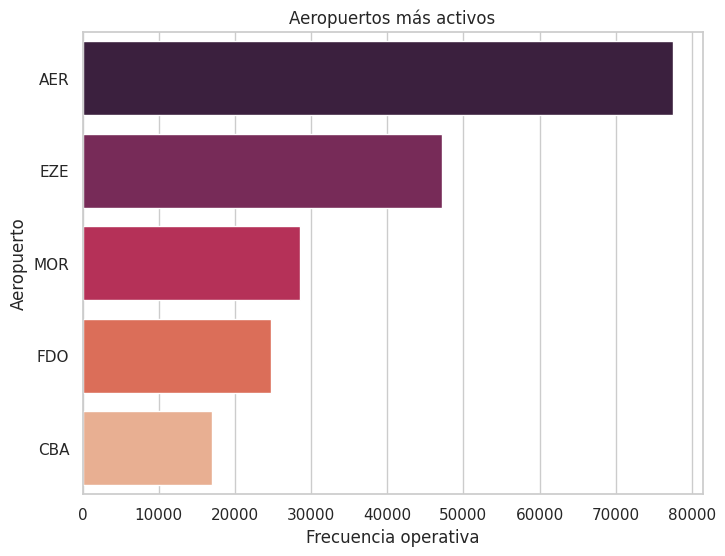

In [ ]:
top_5_aero=data_set_limpio['aeropuerto'].value_counts().head(5)
plt.figure(figsize=(8,6))
sns.barplot(x=top_5_aero.values, y=top_5_aero.index, palette='rocket')
plt.title('Aeropuertos más activos')
plt.xlabel('Frecuencia operativa')
plt.ylabel('Aeropuerto')
plt.show()


Observaciones: Aeroparque Jorge Newbery (AER) en Ciudad Autónoma de Buenos Aires, es el aeropuerto con mayor actividad aerea dentro del país, seguido por Aeropuerto Internacional Ministro Pistarini (EZE) en Buenos Aires, Aeropuerto de Morón (MOR) en Buenos Aires, Aeropuerto Internacional de San Fernando (FDO) en Buenos Aires y Aeropuerto Internacional Ingeniero Ambrosio Taravella (CBA), en Córdoba.

---
###5.3.2 Los 5 Aeropuertos con mayor tráfico de pasajeros
---

In [ ]:
# 1. Se crea una nueva tabla que contenga el total de pasajeros por aeropuerto:
tabla_resumen = data_set_limpio.groupby('aeropuerto')['pasajeros'].sum().reset_index()

# 2. Se rdenan de mayor a menor según el número de pasajeros:
tabla_resumen = tabla_resumen.sort_values(by='pasajeros', ascending=False)

# 3. Tabla resultante
tabla_resumen

,aeropuerto,pasajeros
0,AER,9936762
15,EZE,7261136
4,CBA,1962316
11,DOZ,1349769
1,BAR,1303400
22,IGU,925242
37,SAL,874152
29,NEU,786177
48,USU,665766
46,TUC,537466


/tmp/ipykernel_606/210747596.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_5_tabla, x='aeropuerto', y='pasajeros', palette='coolwarm')


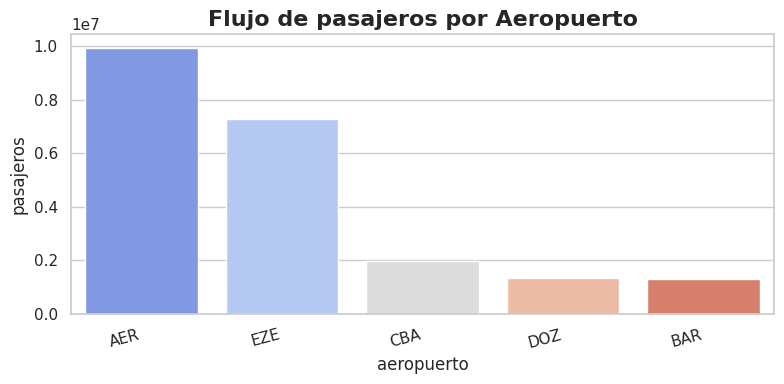

In [ ]:
# Para responde la pregunta sólo se toman las 5 primeras filas de la tabla resumen
top_5_tabla = tabla_resumen.head(5)

plt.figure(figsize=(8, 4))

# Se grafica usando barplot un histograma (porque los datos ya están sumados)
sns.barplot(data=top_5_tabla, x='aeropuerto', y='pasajeros', palette='coolwarm')

plt.title("Flujo de pasajeros por Aeropuerto", fontsize=16, weight='bold')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

Observaciones: el mayor tráfico de pasajeros se encuentra en Aeroparque Jorge Newbery (AER) en Ciudad Autónoma de Buenos Aires, seguido por Aeropuerto Internacional Ministro Pistarini (EZE), Aeropuerto Internacional Ingeniero Ambrosio Taravella (CBA), Aeropuerto Internacional El Plumerillo (DOZ) en Mendoza y el Aeropuerto Internacional Teniente Luis Candelaria (BAR), en Bariloche.

También se puede ver que si bien Aeroparque Jorge Newbery y Aeropuerto Internacional Ministro Pistarini se mantienen en los primeros puestos tanto en actividad como flujo de pasajeros, los aeropuertos que les siguen no son los mismos. El Aeropuerto Internacional Ingeniero Ambrosio Taravella (CBA) que tiene el quinto puesto en actividad aérea, es tercero en flujo de pasajeros.

---
###5.3.3 Flujo de pasajeros en Aeroparque Jorge Newberry por mes
---

In [ ]:
# 1. Se filtran los datos para solo tener los relacionados a Aeroparque Jorge Newberry (AER)
aeropuerto_elegido = "AER"
df_jnewbery = data_set_limpio[data_set_limpio['aeropuerto'] == aeropuerto_elegido]

# 2. Se ordena cronológicamente por fecha para que el flujo tenga sentido
df_jnewbery = df_jnewbery.sort_values(by='fecha_utc')

# Tabla filtrada
df_jnewbery[['fecha_utc', 'pasajeros']]

,fecha_utc,pasajeros
0,2026-01-01,155
700,2026-01-01,170
696,2026-01-01,91
695,2026-01-01,82
693,2026-01-01,213
...,...,...
326149,2026-07-31,83
326148,2026-07-31,167
326145,2026-07-31,236
326170,2026-07-31,144


In [ ]:
# 1.Se busca el total de pasajeros por mes:
tabla_sumada = df_jnewbery.groupby(df_jnewbery['fecha_utc'].dt.to_period('M'))['pasajeros'].sum().reset_index()

# 2. Se ordenan las fechas en orden cronológico mensual y se las convierte a texto para que sea limpio
tabla_sumada = tabla_sumada.sort_values(by='fecha_utc')
tabla_sumada['fecha_utc'] = tabla_sumada['fecha_utc'].astype(str)

# 3. Tabla resultante
tabla_sumada

,fecha_utc,pasajeros
0,2026-01,1563175
1,2026-02,1369097
2,2026-03,1535099
3,2026-04,1422816
4,2026-05,1335263
5,2026-06,1186585
6,2026-07,1524727


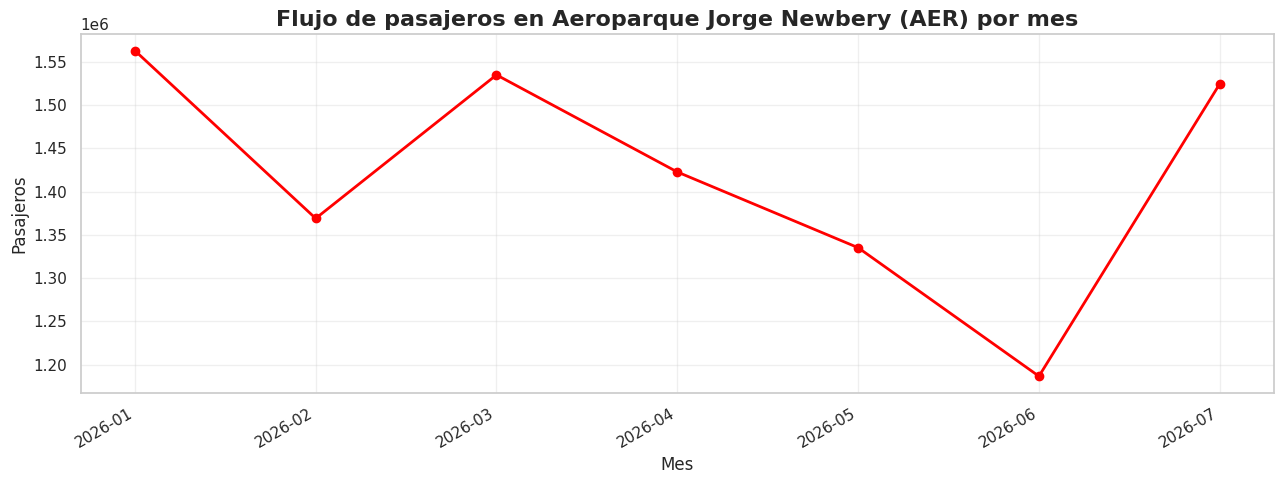

In [ ]:
# Gráfico lineal
plt.figure(figsize=(13, 5))

plt.plot(
    tabla_sumada['fecha_utc'],
    tabla_sumada['pasajeros'],
    marker='o',
    color='red',
    linewidth=2
)

plt.title("Flujo de pasajeros en Aeroparque Jorge Newbery (AER) por mes", fontsize=16, weight='bold')
plt.xlabel("Mes")
plt.ylabel("Pasajeros")
plt.xticks(rotation=30, ha='right') # Evita el amontonamiento de los textos
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Observaciones: en el mes de Enero hay mayor tráfico de pasajeros en Aeroparque Jorge Newbery (AER). El mes de Junio presentó la menor cantidad de flujo con un incremento hacia el mes de Julio.

---
###5.3.4 Clase de vuelo predominante.
---

In [ ]:
# 2. Se filtra de modo de tener solo los datos de Aeroparque Jorge Newberry (AER)
aeropuerto_elegido = "AER"
df_jnewbery2 = data_set_limpio[data_set_limpio['aeropuerto'] == aeropuerto_elegido]

# 3. Ordenamos cronológicamente por fecha para que el flujo tenga sentido
df_jnewbery2 = df_jnewbery2.sort_values(by='clasificación_vuelo')

# Mostramos la tabla filtrada en Colab
df_jnewbery2[['clasificación_vuelo', 'pasajeros']]

,clasificación_vuelo,pasajeros
0,Doméstico,155
203411,Doméstico,156
203415,Doméstico,163
203418,Doméstico,87
203420,Doméstico,96
...,...,...
78724,Internacional,168
78731,Internacional,162
222493,Internacional,148
78653,Internacional,154


In [ ]:
# 1. Se crea una nueva tabla con la suma total de pasajeros según el tipo de vuelo:
tabla_sumada2 = df_jnewbery2.groupby(df_jnewbery2['clasificación_vuelo'])['pasajeros'].sum().reset_index()

# 2. Ordenar las fechas en orden cronológico mensual y convertirlas a texto para que sea limpio
tabla_sumada2 = tabla_sumada2.sort_values(by='clasificación_vuelo')
tabla_sumada2['clasificación_vuelo'] = tabla_sumada2['clasificación_vuelo'].astype(str)

# 3. Mostrar la tabla resultante
tabla_sumada2

,clasificación_vuelo,pasajeros
0,Doméstico,6640818
1,Internacional,3295944


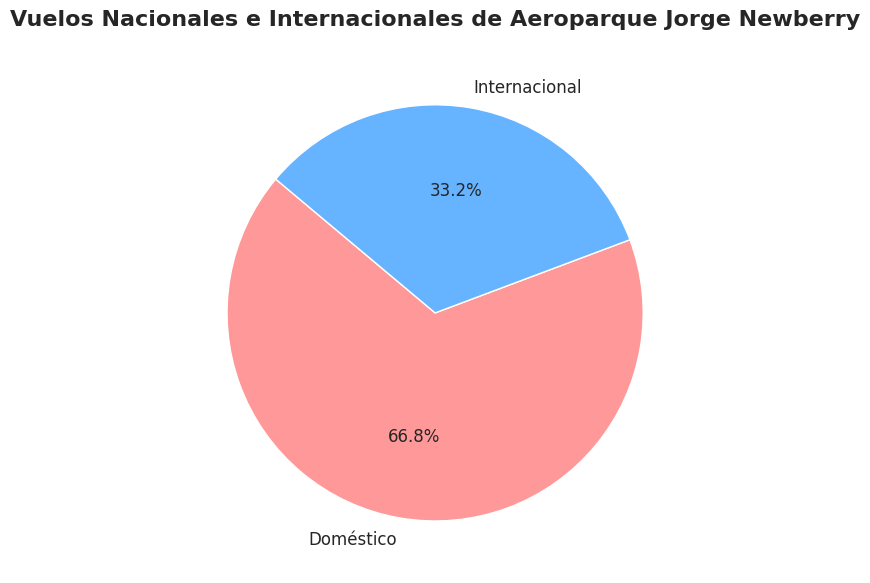

In [ ]:
# 1. Para graficar se usa uno circular o de torta.
plt.figure(figsize=(6, 6))

plt.pie(
    tabla_sumada2['pasajeros'],               # Columna numérica (valores)
    labels=tabla_sumada2['clasificación_vuelo'],       # Columna de texto (categorías)
    autopct='%1.1f%%',                    # Calcula y muestra el porcentaje automáticamente con 1 decimal
    startangle=140,                       # Gira el gráfico para una mejor disposición visual
    colors=['#ff9999','#66b3ff','#99ff99','#ffcc99','#c2c2f0','#ffb3e6'], # Paleta moderna de colores
    textprops={'fontsize': 12}             # Agranda la letra para que se lea perfecto
)

# 3. Título del gráfico
plt.title("Vuelos Nacionales e Internacionales de Aeroparque Jorge Newberry", fontsize=16, weight='bold', pad=20)

plt.tight_layout()
plt.show()

Observaciones: En Aeroparque Jorge Newbery (AER)  predominan los vuelos domésticos osea vuelos nacionales.

---
###5.3.5 Flujo total de pasajeros en territorio Argentino por mes.
---

In [ ]:
# 1. Primero se crea una tabla que contenga la cantidad de pasajeros por mes.
tabla_mensual = data_set_limpio.groupby(data_set_limpio['fecha_utc'].dt.to_period('M'))['pax'].sum().reset_index()

# 3. Se renombran las columnas por proligidad
tabla_mensual.columns = ['Mes', 'pax']

# 4. Se convierte el mes a texto común para que sea fácil de visualizar o graficar
tabla_mensual['Mes'] = tabla_mensual['Mes'].astype(str)

# 5. Tabla resultante
tabla_mensual

,Mes,pax
0,2026-01,3431780
1,2026-02,3032898
2,2026-03,3170075
3,2026-04,2633291
4,2026-05,2401388
5,2026-06,2141843
6,2026-07,2902324


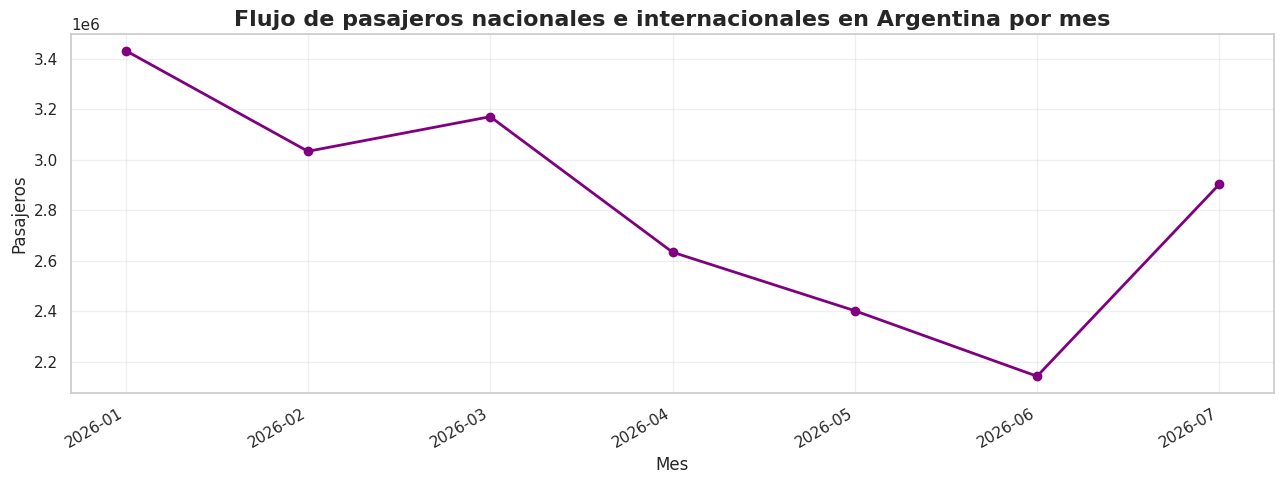

In [ ]:
# Creación del gráfico, para este caso se representan los datos con uno lineal.
plt.figure(figsize=(13, 5))

plt.plot(
    tabla_mensual['Mes'],
    tabla_mensual['pax'],
    marker='o',
    color='purple',
    linewidth=2
)

plt.title("Flujo de pasajeros nacionales e internacionales en Argentina por mes", fontsize=16, weight='bold')
plt.xlabel("Mes")
plt.ylabel("Pasajeros")
plt.xticks(rotation=30, ha='right') # Evita el amontonamiento de los textos
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Observaciones: hasta la última fecha de registros prepondera el flujo de pasajeros de comienzo del año. En marzo se produce una caída vertiginosa del flujo hasta junio, un punto de inflexión a partir del cual remonta nuevamente el a crecimiento.